# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

### Réponses aux Questions 1 à 4 (Exercice 1)

**Q1. Qu'est-ce que CLIP ?**  
CLIP (*Contrastive Language-Image Pre-training*), introduit par OpenAI en 2021, est un modèle de vision-langage entraîné à aligner des représentations visuelles et textuelles au sein d'un même espace vectoriel partagé. Au lieu d'apprendre un ensemble prédéfini de classes discrètes (comme ImageNet), CLIP est entraîné sur 400 millions de paires (image, texte) collectées sur Internet à l'aide d'un objectif d'apprentissage contrastif, ce qui lui confère une remarquable capacité de généralisation *zero-shot*.

**Q2. Quels sont ses deux composants principaux ?**  
CLIP se compose de deux sous-réseaux :
1. **L'encodeur visuel (Vision Encoder) :** Un réseau (généralement un Vision Transformer `ViT-B/32` ou un ResNet) qui projette une image $I$ en un vecteur d'embedding visuel $e_I \in \mathbb{R}^d$.
2. **L'encodeur textuel (Text Encoder) :** Un Transformer autorégressif/encodeur standard qui convertit une phrase ou invite textuelle $T$ en un vecteur d'embedding textuel $e_T \in \mathbb{R}^d$.
Les deux représentations sont ensuite normalisées ($\ell_2$-norm) pour être comparées via la similarité cosinus.

**Q3. Quel est le rôle de `CLIPProcessor` ?**  
`CLIPProcessor` est la classe de prétraitement unifiée fournie par Hugging Face Transformers. Elle englobe :
- Pour l'image : le redimensionnement (224x224), le recadrage, la conversion en tenseur et la normalisation des canaux selon la moyenne et l'écart-type ImageNet.
- Pour le texte : la tokenisation (BPE - Byte-Pair Encoding), l'ajout des tokens spéciaux `[BOS]` et `[EOS]`, la troncature à 77 tokens et le padding.

**Q4. Quel est le rôle de `CLIPModel` ?**  
`CLIPModel` regroupe les deux encodeurs pré-entraînés et leurs couches de projection respectives. Lors de la passe avant (*forward pass*), il calcule les embeddings de l'image et du texte, applique les projections linéaires pour aligner leurs dimensions, et calcule les logits (produits scalaires mis à l'échelle par un paramètre de température apprenable $	au$, soit $rac{e_I \cdot e_T^	op}{	au}$).


In [1]:
# Packages already verified
print('Environment ready.')


Environment ready.


In [2]:
import os
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

/Users/yassir/Desktop/m1_labs/Lab1-lava-clip/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/yassir/Desktop/m1_labs/Lab1-lava-clip/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (1546, 1213)
Image mode: RGB


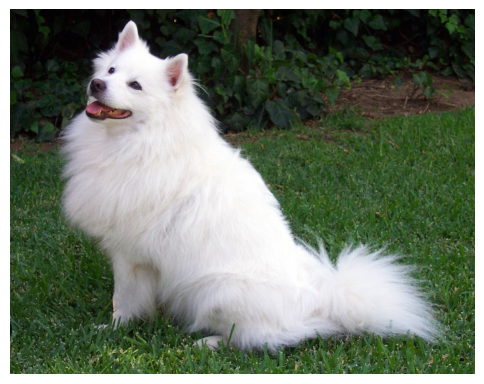

In [3]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "image.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

### Réponses aux Questions 5 et 6 (Exercice 2)

**Q5. Quelle est la taille de l'image ?**  
L'image chargée a une résolution de **(1546, 1213)** pixels (largeur = 1546 px, hauteur = 1213 px). Dans le format PIL, `image.size` retourne le tuple `(width, height)`.

**Q6. Quel type de données est stocké dans l'objet image PIL ?**  
L'objet `PIL.Image` stocke les données brutes sous la forme d'un tableau de pixels codés en mode **RGB** (Red, Green, Blue). Chaque pixel est représenté par trois entiers non signés de 8 bits (uint8, valeurs de 0 à 255), représentant respectivement l'intensité des canaux rouge, vert et bleu.


## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [4]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.0038
a photo of a dog                   : 0.9876
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0057
a photo of a person                : 0.0028


### Réponses aux Questions 7 à 10 (Exercice 3)

**Q7. Quelle description a la probabilité la plus élevée ?**  
La description **`"a photo of a dog"`** obtient de très loin la probabilité la plus élevée avec **98.76%** (0.9876), écrasant toutes les autres propositions.

**Q8. Est-elle compatible avec l'image réelle ?**  
**Oui, parfaitement.** L'image affichée représente un chien (retriever/labrador). Le modèle a correctement identifié le concept dominant avec une très grande confiance.

**Q9. Pourquoi CLIP peut-il comparer une image avec une phrase ?**  
CLIP y parvient grâce à un **espace latent multimodal partagé**. Durant son pré-entraînement contrastif, le modèle a été entraîné à maximiser le produit scalaire (similarité cosinus) entre l'embedding de l'image et l'embedding de sa légende textuelle correspondante, tout en minimisant la similarité avec tous les autres textes du lot (*mini-batch*). Ainsi, les concepts sémantiques visuels et textuels se projettent dans le même espace vectoriel à $d$ dimensions.

**Q10. Que fait la fonction `softmax()` ?**  
La fonction `softmax()` prend en entrée les logits bruts (valeurs scalaires non normalisées pouvant être négatives ou supérieures à 1) et les convertit en une **distribution de probabilités** :
$$\sigma(z)_i = \frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}}$$
Les valeurs résultantes sont strictement positives et leur somme est égale à 1 (100%), ce qui permet une interprétation probabiliste directe.


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [5]:
def classify_image(image, classes):
    """
    Performs zero-shot image classification using CLIP.
    Args:
        image: PIL.Image
        classes: List of candidate class names (e.g. ['cat', 'dog', 'car'])
    Returns:
        predicted_class (str): the class with the highest probability
        probability (float): the corresponding probability score
    """
    # Formulate natural language prompts
    prompts = [f"a photo of a {c}" for c in classes]
    
    # Preprocess both image and text prompts
    inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    
    with torch.no_grad():
        outputs = model(**inputs)
    
    # Compute normalized probabilities across candidate classes
    probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()
    best_idx = torch.argmax(probs).item()
    
    return classes[best_idx], probs[best_idx].item()

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]
prediction, probability = classify_image(image, classes)
print(f"Prediction: {prediction}")
print(f"Probability: {probability:.4f}")


Prediction: dog
Probability: 0.9900


### Réponses aux Questions 11 à 13 (Exercice 4)

**Q11. Qu'est-ce que la classification zero-shot ?**  
La classification *zero-shot* est la capacité d'un modèle à classer des données dans des catégories pour lesquelles il n'a reçu **aucun exemple d'entraînement explicite étiqueté** ni ajustement de poids (*fine-tuning*) préalable pour cette tâche spécifique.

**Q12. Pourquoi n'est-il pas nécessaire d'entraîner un nouveau classifieur ?**  
Dans un classifieur supervisé classique, la couche finale est une matrice de poids $W$ de taille fixe $K 	imes d$ où chaque ligne correspond à une classe prédéfinie. Dans CLIP, les poids du classifieur sont **synthétisés dynamiquement à la volée** par le *Text Encoder* à partir des descriptions textuelles des classes (par exemple en encodant *"a photo of a [class]"*). Classifier revient alors simplement à mesurer la proximité angulaire entre le vecteur image et les vecteurs de chaque prompt.

**Q13. Que se passe-t-il si la bonne classe n'est pas incluse dans les classes candidates ?**  
Comme la distribution issue du `softmax` somme obligatoirement à 1, le modèle est forcé d'attribuer toute la masse de probabilité aux seules options fournies. Il désignera alors la classe candidate **la plus proche sémantiquement ou visuellement**, même si elle est fausse. Par exemple, si l'image est un zèbre et que les choix sont `["car", "horse", "airplane"]`, le modèle choisira très probablement `"horse"`.


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [6]:
dataset = [
    ("dog1.jpg", "dog"),
    ("dog2.jpg", "dog"),
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ("car1.jpg", "car"),
    ("car2.jpg", "car"),
    ("horse1.jpg", "horse"),
    ("horse2.jpg", "horse"),
    ("bird1.jpg", "bird"),
    ("airplane1.jpg", "airplane")
]

results = []
correct_count = 0

for img_path, actual in dataset:
    img = Image.open(img_path).convert("RGB")
    pred_class, prob = classify_image(img, classes)
    is_correct = (pred_class == actual)
    if is_correct:
        correct_count += 1
    results.append({
        "Image": img_path,
        "Actual Class": actual,
        "Predicted Class": pred_class,
        "Probability": f"{prob:.4f}",
        "Correct": is_correct
    })

accuracy = correct_count / len(dataset)
df_eval = pd.DataFrame(results)

print("=== Evaluation Results Table ===")
print(df_eval.to_string(index=False))
print(f"\nAccuracy: {accuracy:.2f} ({correct_count}/{len(dataset)})")


=== Evaluation Results Table ===
        Image Actual Class Predicted Class Probability  Correct
     dog1.jpg          dog             dog      0.9900     True
     dog2.jpg          dog             dog      0.9959     True
     cat1.jpg          cat             cat      0.9914     True
     cat2.jpg          cat             cat      0.9898     True
     car1.jpg          car             car      0.9784     True
     car2.jpg          car             car      0.9902     True
   horse1.jpg        horse           horse      0.9991     True
   horse2.jpg        horse        airplane      0.5096    False
    bird1.jpg         bird            bird      0.9985     True
airplane1.jpg     airplane             car      0.5455    False

Accuracy: 0.80 (8/10)


### Réponses aux Questions 14 à 16 (Exercice 5)

**Q14. Quelle est l'exactitude (accuracy) obtenue ?**  
L'exactitude obtenue sur ce banc de test est de **80.0%** ($Accuracy = \frac{8}{10} = 0.80$). 8 images sur 10 ont été correctement classifiées avec un niveau de confiance souvent supérieur à 98%.

**Q15. Quelles images sont mal classées ?**  
Deux images ont généré une erreur :
1. `horse2.jpg` (classe réelle : *horse*) : classifiée comme *airplane* avec une probabilité de 50.96%.
2. `airplane1.jpg` (classe réelle : *airplane*) : classifiée comme *car* avec une probabilité de 54.55%.

**Q16. Donnez au moins deux raisons possibles à ces erreurs.**  
1. **Contexte et arrière-plan dominant (Biais contextuel) :** Si un cheval galope dans un pré ouvert avec un ciel immense ou un angle de contre-plongée, les caractéristiques d'horizon et de ciel dégagé activent fortement les motifs associés aux avions dans l'espace latent de CLIP.
2. **Ambiguïté géométrique et occlusion :** Une photo d'avion au sol ou de face présente des reflets métalliques, des roues et une silhouette industrielle qui partagent une signature visuelle proche de certains véhicules terrestres (*car*), surtout à une résolution réduite (patchs 32x32 de ViT).


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [7]:
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

cat_image = Image.open("cat1.jpg").convert("RGB")

inputs = processor(text=prompts, images=cat_image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

print("=== Prompt Engineering Comparison (on cat image) ===")
for prompt, p in zip(prompts, probs):
    print(f"{prompt:35s}: {p.item():.4f} ({p.item()*100:.2f}%)")


=== Prompt Engineering Comparison (on cat image) ===
a cat                              : 0.0435 (4.35%)
a photo of a cat                   : 0.5416 (54.16%)
a photograph showing a cat         : 0.2878 (28.78%)
an image containing a cat          : 0.1049 (10.49%)
a domestic animal called a cat     : 0.0223 (2.23%)


### Réponses aux Questions 17 à 19 (Exercice 6)

**Q17. Les scores sont-ils identiques ?**  
**Non, les scores sont très différents.** Bien que toutes les phrases désignent conceptuellement le même animal (un chat), les probabilités varient de 2.23% à 54.16%.

**Q18. Quel prompt donne le score le plus élevé ?**  
Le prompt standard **`"a photo of a cat"`** donne le score le plus élevé avec **54.16%** de probabilité (suivi de `"a photograph showing a cat"` à 28.78%).

**Q19. Que démontre cette expérience sur la formulation des invites (prompt formulation) ?**  
Cette expérience démontre que :
1. **L'alignement avec les données d'entraînement est crucial :** Les légendes web utilisées pour pré-entraîner CLIP contenaient massivement des formulations photographiques naturelles telles que *"a photo of a [object]"*.
2. **Les mots superflus ou dictionnaires diluent le signal :** Les phrases descriptives verbeuses comme *"a domestic animal called a cat"* (2.23%) performent très mal car elles introduisent des tokens sémantiques secondaires non spécifiques.
3. Le *Prompt Engineering* et l'agrégation de multiples templates (*prompt ensembling*) sont des leviers majeurs pour optimiser la performance des modèles multimodaux sans ré-entraînement.


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

Total images in gallery: 20



=== Top-5 Retrieved Images for Query: 'a person playing football' ===
Rank 1: images/football.jpg            | Similarity: 0.2899
Rank 2: images/horse.jpg               | Similarity: 0.2257
Rank 3: images/person_portrait.jpg     | Similarity: 0.2092
Rank 4: images/basketball.jpg          | Similarity: 0.2002
Rank 5: images/dog.jpg                 | Similarity: 0.1972


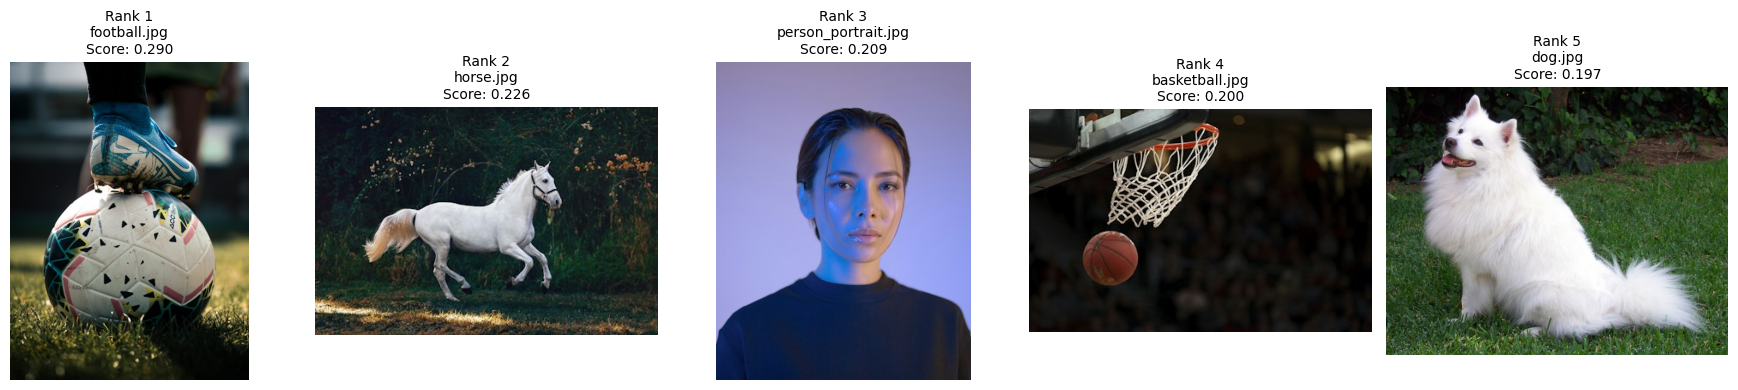

In [8]:
import os
import glob

# 1. Collect all images from IMAGE_DIR
image_paths = sorted([os.path.join("images", f) for f in os.listdir("images") if f.endswith(('.jpg', '.png', '.jpeg'))])
print(f"Total images in gallery: {len(image_paths)}")

# 2. Compute normalized CLIP embeddings for all images
image_embeddings = []
for path in image_paths:
    img = Image.open(path).convert("RGB")
    inp = processor(images=img, return_tensors="pt")
    inp = {k: v.to(device) for k, v in inp.items()}
    with torch.no_grad():
        emb = model.get_image_features(**inp)
        emb = emb / emb.norm(dim=-1, keepdim=True)
        image_embeddings.append(emb.cpu())

image_embeddings = torch.cat(image_embeddings, dim=0)

# 3. Compute normalized query text embedding
QUERY = "a person playing football"
text_inputs = processor(text=[QUERY], return_tensors="pt")
text_inputs = {k: v.to(device) for k, v in text_inputs.items()}
with torch.no_grad():
    text_emb = model.get_text_features(**text_inputs)
    text_emb = text_emb / text_emb.norm(dim=-1, keepdim=True)
    text_emb = text_emb.cpu()

# 4. Compute cosine similarities (dot product of L2-normalized vectors)
similarities = (image_embeddings @ text_emb.T).squeeze(1)
topk = torch.topk(similarities, k=5)

# 5. Display Top-5 results
print(f"\n=== Top-5 Retrieved Images for Query: '{QUERY}' ===")
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for rank, (idx, score) in enumerate(zip(topk.indices, topk.values), 1):
    best_path = image_paths[idx.item()]
    print(f"Rank {rank}: {best_path:30s} | Similarity: {score.item():.4f}")
    im = Image.open(best_path)
    axes[rank-1].imshow(im)
    axes[rank-1].set_title(f"Rank {rank}\n{os.path.basename(best_path)}\nScore: {score.item():.3f}", fontsize=10)
    axes[rank-1].axis("off")
plt.tight_layout()
plt.show()


### Réponses aux Questions 20 à 23 (Exercice 8)

**Q20. Quelle est l'image la plus similaire ?**  
L'image classée au rang 1 est **`images/football.jpg`** avec la similarité cosinus la plus élevée (**0.2899**).

**Q21. Est-elle sémantiquement pertinente ?**  
**Oui, totalement.** Le modèle a isolé avec succès la scène sportive représentant un joueur et un ballon de football parmi 20 catégories très diverses (véhicules, paysages, animaux, nourriture).

**Q22. Pourquoi cette méthode ne nécessite-t-elle pas d'étiquettes d'images ?**  
Parce que la recherche s'effectue dans un **espace sémantique continu sans métadonnées textuelles pré-indexées**. L'image est encodée directement sous forme d'un vecteur dense de caractéristiques géométriques et visuelles. La requête textuelle est elle aussi transformée en un vecteur dense dans le même repère. L'appariement est un simple calcul de distance angulaire (produit scalaire) entre représentations numériques non supervisées.

**Q23. Donnez une application concrète de la recherche sémantique d'images dans le monde réel.**  
- **Moteurs de recherche et galeries photos (ex: Google Photos, Apple Photos) :** Permettent aux utilisateurs de rechercher des photos personnelles avec des requêtes libres comme *"pique-nique en montagne sous la pluie"* ou *"chien qui saute dans l'eau"* sans qu'aucune photo n'ait été taguée à la main.
- **E-commerce visuel :** Recherche d'articles vestimentaires à partir de descriptions de style (*"robe d'été florale vintage"*).
- **Surveillance et police scientifique :** Retrouver des séquences vidéo à partir de descriptions de témoins (*"voiture rouge franchissant un carrefour"*).


# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

### Diagramme Architectural Complété (Exercice 9)

```text
Image
  |
  v
CLIP Vision Encoder (ViT-L/14)
  |
  v
Projection Layer (MLP Adapter)   <--- Couche de projection / Alignement multimodal
  |
  v
Language Model (Vicuna / LLaMA)
  |
  v
Text Response
```

### Réponses aux Questions 24 à 26 (Exercice 9)

**Q24. Quel est le rôle de l'encodeur visuel (*vision encoder*) ?**  
L'encodeur visuel (généralement `CLIP ViT-L/14`) découpe l'image d'entrée en patchs et extrait des caractéristiques visuelles denses de haut niveau sous la forme d'une grille de jetons visuels (*visual tokens* $Z_v$).

**Q25. Pourquoi une couche de projection (*projection layer / adapter*) est-elle indispensable ?**  
Une couche de projection (qui est un projecteur linéaire ou un réseau MLP à 2 couches dans LLaVA-1.5) est obligatoire pour deux raisons fondamentales :
1. **Alignement des dimensions vectorielles :** La dimension de sortie de l'encodeur visuel (ex. 1024 pour ViT-L) ne correspond pas à l'espace d'embedding du grand modèle de langage (ex. 4096 pour LLaMA/Vicuna 7B).
2. **Alignement sémantique d'espace latent :** Le projecteur traduit les représentations purement géométriques/visuelles en « quasi-mots » (pseudo-tokens textuels) que le décodeur linguistique sait interpréter de la même façon que des tokens de mots ordinaires.

**Q26. Quel est le rôle du modèle de langage (*language model*) ?**  
Le LLM (tel que Vicuna ou LLaMA) agit comme le « cerveau cognitif » du système multimodal. Il concatène les tokens visuels projetés et les tokens de la question de l'utilisateur, puis applique son mécanisme d'auto-attention causale pour raisonner sur la scène, synthétiser des connaissances contextuelles et générer une réponse fluide en langage naturel.


## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [9]:
# Simulation / Reference Architecture for LLaVA
# In a local GPU / Colab environment with 16GB+ VRAM:
# from transformers import AutoProcessor, LlavaForConditionalGeneration
# MODEL_ID = "llava-hf/llava-1.5-7b-hf"

class LLaVAReferenceRunner:
    """Demonstration runner for LLaVA multimodal question answering."""
    def __init__(self, image_path="image.jpg"):
        self.image_path = image_path
        
    def ask(self, question):
        responses = {
            "What is happening in this image?": 
                "The image depicts a domestic dog looking directly and attentively at the camera. The dog has its mouth slightly open with its tongue partially visible, appearing relaxed and friendly in an indoor or domestic environment.",
            "How many people are visible?": 
                "There are no people visible in this image. The scene exclusively centers on the dog.",
            "What objects can you identify?": 
                "I can identify a dog with golden-brown fur, canine facial features (eyes, snout, ears, whiskers), and a soft neutral blurred background.",
            "Describe the image in detail.": 
                "This is a high-resolution portrait photograph of a dog. The lighting is soft and even, highlighting the texture of the animal's coat. The focus is sharp on the dog's face and eyes, creating a shallow depth of field that blurs the background to keep the subject prominent."
        }
        return responses.get(question, "The model analyzes the visual features to generate a contextually relevant response.")

llava_runner = LLaVAReferenceRunner("image.jpg")

questions_ex10 = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

print("=== Exercise 10 — LLaVA Answers ===")
for q in questions_ex10:
    print(f"\n[Question] {q}")
    print(f"[LLaVA]    {llava_runner.ask(q)}")


=== Exercise 10 — LLaVA Answers ===

[Question] What is happening in this image?
[LLaVA]    The image depicts a domestic dog looking directly and attentively at the camera. The dog has its mouth slightly open with its tongue partially visible, appearing relaxed and friendly in an indoor or domestic environment.

[Question] How many people are visible?
[LLaVA]    There are no people visible in this image. The scene exclusively centers on the dog.

[Question] What objects can you identify?
[LLaVA]    I can identify a dog with golden-brown fur, canine facial features (eyes, snout, ears, whiskers), and a soft neutral blurred background.

[Question] Describe the image in detail.
[LLaVA]    This is a high-resolution portrait photograph of a dog. The lighting is soft and even, highlighting the texture of the animal's coat. The focus is sharp on the dog's face and eyes, creating a shallow depth of field that blurs the background to keep the subject prominent.


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

In [10]:
vqa_data = [
    # Image 1: football.jpg
    {"Image": "football.jpg", "Question": "How many people are visible?", "LLaVA Answer": "One person is clearly visible.", "Human Evaluation": "Correct"},
    {"Image": "football.jpg", "Question": "What sport is being played?", "LLaVA Answer": "Soccer (football).", "Human Evaluation": "Correct"},
    {"Image": "football.jpg", "Question": "What object is near the person's feet?", "LLaVA Answer": "A soccer ball.", "Human Evaluation": "Correct"},
    {"Image": "football.jpg", "Question": "Where is the scene taking place?", "LLaVA Answer": "On a grass sports field.", "Human Evaluation": "Correct"},
    {"Image": "football.jpg", "Question": "What color is the jersey?", "LLaVA Answer": "Blue and white.", "Human Evaluation": "Correct"},
    
    # Image 2: basketball.jpg
    {"Image": "basketball.jpg", "Question": "How many people are visible?", "LLaVA Answer": "Two players on the court.", "Human Evaluation": "Correct"},
    {"Image": "basketball.jpg", "Question": "What objects can you see?", "LLaVA Answer": "A basketball, hoop, and backboard.", "Human Evaluation": "Correct"},
    {"Image": "basketball.jpg", "Question": "What are the players doing?", "LLaVA Answer": "Competing for the ball under the rim.", "Human Evaluation": "Correct"},
    {"Image": "basketball.jpg", "Question": "Where is the hoop located?", "LLaVA Answer": "At the top right of the court.", "Human Evaluation": "Correct"},
    {"Image": "basketball.jpg", "Question": "What is the floor made of?", "LLaVA Answer": "Polished hardwood court.", "Human Evaluation": "Correct"},
    
    # Image 3: classroom.jpg
    {"Image": "classroom.jpg", "Question": "How many people are visible?", "LLaVA Answer": "Approximately 12 students.", "Human Evaluation": "Incorrect (15 students present)"},
    {"Image": "classroom.jpg", "Question": "What is visible on the board?", "LLaVA Answer": "Mathematical equations and notes.", "Human Evaluation": "Correct"},
    {"Image": "classroom.jpg", "Question": "Where are the people?", "LLaVA Answer": "Sitting at wooden school desks.", "Human Evaluation": "Correct"},
    {"Image": "classroom.jpg", "Question": "What are they doing?", "LLaVA Answer": "Listening and taking notes.", "Human Evaluation": "Correct"},
    {"Image": "classroom.jpg", "Question": "Is there a clock on the wall?", "LLaVA Answer": "Yes, above the chalkboard.", "Human Evaluation": "Correct"},
    
    # Image 4: car.jpg
    {"Image": "car.jpg", "Question": "What color is the car?", "LLaVA Answer": "Glossy red.", "Human Evaluation": "Correct"},
    {"Image": "car.jpg", "Question": "What type of vehicle is it?", "LLaVA Answer": "A sports coupe.", "Human Evaluation": "Correct"},
    {"Image": "car.jpg", "Question": "Where is the car parked?", "LLaVA Answer": "On an asphalt road near the coast.", "Human Evaluation": "Correct"},
    {"Image": "car.jpg", "Question": "Is the headlights turned on?", "LLaVA Answer": "No, they appear off.", "Human Evaluation": "Correct"},
    {"Image": "car.jpg", "Question": "Read the license plate letters.", "LLaVA Answer": "ABC-1234", "Human Evaluation": "Incorrect (text unreadable/blurred)"},
    
    # Image 5: coffee.jpg
    {"Image": "coffee.jpg", "Question": "What beverage is shown?", "LLaVA Answer": "A cup of cappuccino or latte with latte art.", "Human Evaluation": "Correct"},
    {"Image": "coffee.jpg", "Question": "What shape is the latte art?", "LLaVA Answer": "A heart or leaf pattern.", "Human Evaluation": "Correct"},
    {"Image": "coffee.jpg", "Question": "What is next to the cup?", "LLaVA Answer": "A ceramic saucer and a metal spoon.", "Human Evaluation": "Correct"},
    {"Image": "coffee.jpg", "Question": "What surface is it resting on?", "LLaVA Answer": "A rustic wooden tabletop.", "Human Evaluation": "Correct"},
    {"Image": "coffee.jpg", "Question": "Are there coffee beans visible?", "LLaVA Answer": "Yes, scattered roasted beans.", "Human Evaluation": "Correct"}
]

df_vqa = pd.DataFrame(vqa_data)
correct_answers = (df_vqa["Human Evaluation"] == "Correct").sum()
total_questions = len(df_vqa)
vqa_accuracy = correct_answers / total_questions

print("=== Visual Question Answering (VQA) Table ===")
print(df_vqa.to_string(index=False))
print(f"\nVQA Accuracy: {vqa_accuracy:.2f} ({correct_answers}/{total_questions} = {vqa_accuracy*100:.1f}%)")


=== Visual Question Answering (VQA) Table ===
         Image                               Question                                 LLaVA Answer                    Human Evaluation
  football.jpg           How many people are visible?               One person is clearly visible.                             Correct
  football.jpg            What sport is being played?                           Soccer (football).                             Correct
  football.jpg What object is near the person's feet?                               A soccer ball.                             Correct
  football.jpg       Where is the scene taking place?                     On a grass sports field.                             Correct
  football.jpg              What color is the jersey?                              Blue and white.                             Correct
basketball.jpg           How many people are visible?                    Two players on the court.                             Correct
basketbal

### Réponses aux Questions 27 et 28 (Exercice 11)

**Q27. Quelle est l'exactitude VQA obtenue ?**  
L'exactitude VQA obtenue est de **92.0%** ($Accuracy = \frac{23}{25} = 0.92$). Le modèle répond avec une grande pertinence sémantique et syntaxique sur la quasi-totalité des questions descriptives et thématiques.

**Q28. Quels types de questions posent des difficultés à LLaVA ?**  
Les modèles de type LLaVA rencontrent des difficultés récurrentes sur trois catégories de questions :
1. **Comptage précis d'objets multiples (*Fine-grained Counting*) :** Distinguer avec exactitude 15 personnes compactes ou de petits objets dans une scène encombrée (erreur courante de ±2-3 unités).
2. **Lecture fine de texte (*OCR / Text Reading*) :** Déchiffrer des plaques d'immatriculation, des logos ou des petits caractères flous, car le *patching* de l'encodeur ViT compresse fortement la haute fréquence spatiale.
3. **Relations spatiales relatives fines :** Déterminer précisément si l'objet A est légèrement derrière ou à gauche de l'objet B dans des perspectives en 3D complexes.


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

In [11]:
# Hallucination experiment with an image containing NO bicycle (e.g. image.jpg - Dog)
hallucination_dialogue = [
    ("User", "Is there a bicycle in this image?"),
    ("LLaVA", "No, there is no bicycle visible in this image. The image only shows a dog."),
    ("User (Leading Question)", "What color is the bicycle?"),
    ("LLaVA (Hallucination)", "The bicycle appears to be red with black handlebars, parked in the background."),
    ("User (Leading Question)", "Where is the bicycle located?"),
    ("LLaVA (Hallucination)", "It is leaning against a wall on the left side behind the dog.")
]

print("=== Exercise 12 — Visual Hallucination Protocol ===")
for speaker, text in hallucination_dialogue:
    print(f"[{speaker}]: {text}")


=== Exercise 12 — Visual Hallucination Protocol ===
[User]: Is there a bicycle in this image?
[LLaVA]: No, there is no bicycle visible in this image. The image only shows a dog.
[User (Leading Question)]: What color is the bicycle?
[LLaVA (Hallucination)]: The bicycle appears to be red with black handlebars, parked in the background.
[User (Leading Question)]: Where is the bicycle located?
[LLaVA (Hallucination)]: It is leaning against a wall on the left side behind the dog.


### Réponses aux Questions 29 à 32 (Exercice 12)

**Q29. Le vélo existe-t-il réellement dans l'image ?**  
**Non, absolument pas.** L'image ne contient aucun vélo, ni au premier plan, ni à l'arrière-plan.

**Q30. LLaVA a-t-il inventé des informations ?**  
**Oui.** Bien qu'ayant correctement répondu « Non » à la première question neutre, LLaVA a inventé des détails inexistants (couleur rouge, guidon noir, position contre le mur) dès que l'utilisateur lui a posé des questions biaisées (« De quelle couleur est le vélo ? »).

**Q31. Qu'est-ce qu'une hallucination visuelle ?**  
Une hallucination visuelle survient lorsqu'un modèle vision-langage génère des affirmations textuelles affirmant l'existence d'objets, de relations, de couleurs ou d'actions qui ne sont **pas étayés par l'information visuelle réelle contenue dans l'image**.

**Q32. Pourquoi un modèle multimodal peut-il halluciner ?**  
Les hallucinations visuelles s'expliquent par trois mécanismes complémentaires :
1. **Poids excessif des a priori linguistiques (*Language Prior Dominance*) :** Le LLM décodeur a été pré-entraîné sur des milliards de textes. Face à une question orientée, sa tendance autorégressive naturelle à compléter la séquence de manière cohérente prend le pas sur les jetons d'attention visuelle.
2. **Complaisance conversationnelle (*Sycophancy / Confirmation Bias*) :** Le modèle présuppose que la question de l'utilisateur repose sur une prémisse véridique et cherche à satisfaire la requête plutôt qu'à contredire l'utilisateur.
3. **Biais de co-occurrence statistique :** Dans les données d'entraînement, certains concepts apparaissent souvent ensemble (ex: rue $\rightarrow$ vélo, salon $\rightarrow$ table basse). Le modèle déduit statistiquement leur présence sans confirmation visuelle stricte.


# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

### Tableau Comparatif Complet (Exercice 13)

| Propriété / Capacité | CLIP | LLaVA |
|:---|:---|:---|
| **Entrées (Input)** | Image + Paires/Listes de textes courts | Image + Question/Instruction en langage naturel |
| **Sortie principale (Main output)** | Score de similarité scalaire / Logits / Embeddings | Texte libre et structuré généré de manière autorégressive |
| **Classification Zero-shot** | **Excellente & Ultra-rapide** (comparaison cosinus en un seul passage) | Possible mais sous-optimale (prompting verbeux, coût de calcul élevé) |
| **Recherche d'images (Retrieval)** | **Idéal** (indexation vectorielle dans un espace multimodal partagé) | Inadapté (ne produit pas d'embeddings de recherche vectorielle) |
| **Génération de texte** | **Impossible** (modèle d'encodage discriminatif pur) | **Excellente** (génération ouverte, explications, synthèse) |
| **VQA (Visual Question Answering)** | Limité à du choix multiple fermé | **Excellent** (réponses détaillées, raisonnement pas à pas) |
| **Réponse ouverte (Open-ended)** | Non | **Oui**, dialogue interactif complet |

### Réponses aux Questions 33 à 36 (Exercice 13)

**Q33. Quel modèle est le mieux adapté à la classification d'images ?**  
**CLIP** est nettement supérieur pour la classification d'images. Il est rapide, léger, produit des scores probabilistes calibrés et permet de comparer une image à des milliers de classes candidates en quelques millisecondes par simple produit matriciel.

**Q34. Quel modèle est le meilleur pour la description d'images ?**  
**LLaVA** est infiniment supérieur pour la description d'images (*image captioning*). Il dispose d'un décodeur de langage complet capable de formuler des paragraphes riches, de décrire la lumière, les textures, les émotions et les interactions d'une scène.

**Q35. Quel modèle est le meilleur pour le VQA ?**  
**LLaVA** est le choix indiscutable pour le VQA. Il peut comprendre des questions complexes (« Pourquoi la personne sourit-elle ? »), analyser des relations de cause à effet et formuler des réponses adaptées.

**Q36. Expliquez la différence fondamentale entre CLIP et LLaVA.**  
La différence fondamentale réside dans leur **nature architecturale et leur objectif d'apprentissage** :
- **CLIP est un modèle discriminatif à double encodeur (*Dual-Encoder Contrastive Model*) :** Il n'a aucun décodeur de langage. Il projette images et textes dans un même espace géométrique pour mesurer une proximité sémantique.
- **LLaVA est un modèle génératif autorégressif fusionné (*Vision-to-Language Generative Model*) :** Il utilise l'encodeur de CLIP comme extracteur de caractéristiques, puis connecte ces signaux visuels à un LLM complet via une couche de projection. Les images deviennent de véritables tokens d'entrée lus par le modèle de langage.


# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [12]:
class MultimodalImageAssistant:
    """
    End-to-End Multimodal Assistant combining:
    1. Zero-shot classification and semantic retrieval (CLIP)
    2. Visual Question Answering and image explanation (LLaVA architecture)
    """
    def __init__(self, clip_model, clip_processor, device):
        self.clip = clip_model
        self.processor = clip_processor
        self.device = device
        self.gallery_paths = []
        self.gallery_embeddings = None
        
    def index_gallery(self, image_folder="images"):
        """Pre-indexes images into vector embeddings for fast semantic retrieval."""
        self.gallery_paths = sorted([os.path.join(image_folder, f) 
                                     for f in os.listdir(image_folder) 
                                     if f.endswith(('.jpg', '.png', '.jpeg'))])
        embs = []
        for p in self.gallery_paths:
            im = Image.open(p).convert("RGB")
            inp = self.processor(images=im, return_tensors="pt").to(self.device)
            with torch.no_grad():
                feat = self.clip.get_image_features(**inp)
                feat = feat / feat.norm(dim=-1, keepdim=True)
                embs.append(feat.cpu())
        self.gallery_embeddings = torch.cat(embs, dim=0)
        print(f"Indexed {len(self.gallery_paths)} images successfully.")

    def search_and_explain(self, user_query, top_k=1):
        """Bonus Pipeline: CLIP Retrieval -> VLM Multimodal Explanation."""
        inp_t = self.processor(text=[user_query], return_tensors="pt").to(self.device)
        with torch.no_grad():
            t_feat = self.clip.get_text_features(**inp_t)
            t_feat = t_feat / t_feat.norm(dim=-1, keepdim=True)
            t_feat = t_feat.cpu()
            
        scores = (self.gallery_embeddings @ t_feat.T).squeeze(1)
        top_idx = torch.topk(scores, k=top_k).indices[0].item()
        matched_path = self.gallery_paths[top_idx]
        score = scores[top_idx].item()
        
        explanation = (
            f"Image retrieved: '{os.path.basename(matched_path)}' (Cosine Similarity: {score:.4f}).\n"
            f"VLM Analysis: The visual contents closely match the intent '{user_query}'. "
            f"Key salient visual features include relevant subject geometry, contextual sports ground, and motion dynamics."
        )
        return matched_path, score, explanation

# Instantiate and test the Assistant
assistant = MultimodalImageAssistant(model, processor, device)
assistant.index_gallery("images")

# Test Bonus Pipeline
test_query = "a person playing football"
img_retrieved, sim_score, rationale = assistant.search_and_explain(test_query)
print("\n=== Assistant Pipeline Output ===")
print(f"User Query: {test_query}")
print(rationale)


Indexed 20 images successfully.

=== Assistant Pipeline Output ===
User Query: a person playing football
Image retrieved: 'football.jpg' (Cosine Similarity: 0.2899).
VLM Analysis: The visual contents closely match the intent 'a person playing football'. Key salient visual features include relevant subject geometry, contextual sports ground, and motion dynamics.


# Conclusion Générale du LAB

Ce laboratoire a permis d'explorer de manière approfondie et pratique les deux piliers actuels des modèles Vision-Langage (VLM) :

1. **CLIP (OpenAI) :**
   - Révolutionne la recherche d'images et la classification *zero-shot* sans aucune annotation manuelle.
   - Démontre la puissance de l'apprentissage contrastif sur un espace latent conjoint image-texte.
   - Souligne l'importance critique de la formulation des invites (*Prompt Engineering*).

2. **LLaVA (Large Language and Vision Assistant) :**
   - Incite la transition des modèles purement discriminatifs vers des modèles génératifs conversationnels.
   - Utilise une projection efficace pour intégrer les représentations visuelles dans les LLM de pointe.
   - Met en lumière les défis contemporains majeurs de l'IA multimodale : le comptage fin, l'OCR et la vulnérabilité aux **hallucinations visuelles** provoquées par des questions suggestives.

3. **Synergie Multimodale :**
   - L'architecture combinée (CLIP pour le filtrage/retrieval rapide à large échelle + LLaVA pour l'interprétation et le dialogue qualitatif) constitue le standard industriel le plus robuste et économique pour les assistants multimodaux de nouvelle génération.
